<a href="https://colab.research.google.com/github/Andrew-lee0615/value-at-risk-analysis/blob/main/03_parametric_var.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf


In [2]:

tickers = ["NVDA","INTC", "AMD", "MU", "MRVL", "WDC", "AVGO", "SPY"]
prices = yf.download(tickers, period="5y", auto_adjust=True)["Close"]
prices.tail()


[*********************100%***********************]  8 of 8 completed


Ticker,AMD,AVGO,INTC,MRVL,MU,NVDA,SPY,WDC
Date,,,,,,,,
2026-10-12,594.239990,354.730011,101.349998,265.859985,988.884338,226.320007,778.099976,386.940002
2026-10-13,605.530029,357.309998,102.809998,268.730011,953.040039,228.520004,778.010010,380.709991
2026-10-14,570.820007,346.250000,98.120003,245.279999,914.130005,221.300003,769.599976,364.100006
2026-10-15,562.229980,344.329987,95.370003,241.240005,931.239990,217.229996,771.789978,356.450012
2026-10-16,528.750000,328.750000,89.849998,227.830002,878.840027,214.130005,763.250000,332.000000


In [3]:
log_returns = np.log(prices / prices.shift(1)).dropna()
log_returns.head()

Ticker,AMD,AVGO,INTC,MRVL,MU,NVDA,SPY,WDC
Date,,,,,,,,
2021-10-19,-0.000859,0.013870,0.013494,0.010073,0.004598,0.003055,0.007685,0.004503
2021-10-20,0.000516,-0.001961,0.002894,-0.009775,0.010306,-0.008425,0.003920,0.013564
2021-10-21,0.024946,0.009301,0.011314,-0.001788,0.005405,0.026299,0.002605,0.006890
2021-10-22,0.004098,0.002448,-0.124187,-0.011396,-0.016600,0.001497,-0.001037,0.004392
2021-10-25,0.020977,0.012839,-0.001011,0.020302,0.018347,0.019176,0.005348,-0.003864


In [7]:
stocks = ["NVDA","INTC","AMD","MU","MRVL","WDC","AVGO"]
port = log_returns[stocks].mean(axis=1)
port.head()

,0
Date,
2021-10-19,0.006962
2021-10-20,0.001017
2021-10-21,0.011767
2021-10-22,-0.019964
2021-10-25,0.012395


In [8]:
port_var_95 = -port.quantile(0.05)
port_var_99 = -port.quantile(0.01)
print(port_var_95)
print(port_var_99)


0.04230151447953849
0.0693489156521325


In [10]:
mu = port.mean()
sigma = port.std()

param_var_95 = 1.645 * sigma - mu
param_var_99 = 2.326 * sigma - mu
print(param_var_95)
print(param_var_99)

0.04285079798891253
0.06116747112482927


In [11]:
compare = pd.DataFrame({
    "Historical": [port_var_95, port_var_99],
    "Parametric": [param_var_95, param_var_99]
}, index=["95% VaR", "99% VaR"])
compare

,Historical,Parametric
95% VaR,0.042302,0.042851
99% VaR,0.069349,0.061167


## Key Finding
Historical and parametric VaR are almost identical at 95% (4.23% vs 4.29%), but at 99% the parametric method underestimates risk by about 12% (6.12% vs 6.93%). Real returns are not normally distributed: they have fat tails, so large losses happen more often than the normal model predicts.

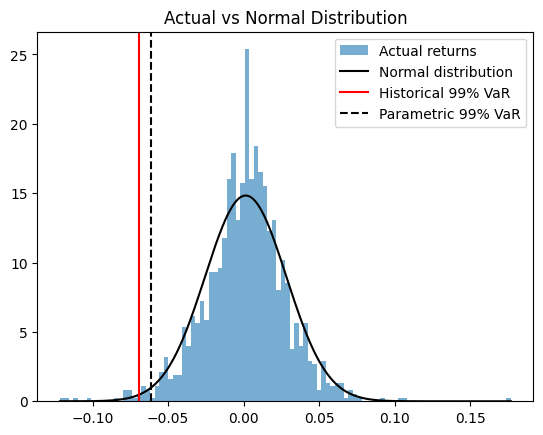

In [13]:
from scipy.stats import norm
import matplotlib.pyplot as plt

x = np.linspace(port.min(), port.max(), 500)

plt.hist(port, bins=100, density=True, alpha=0.6, label="Actual returns")
plt.plot(x, norm.pdf(x, port.mean(), port.std()), color="black", label="Normal distribution")
plt.axvline(-port_var_99, color="red", label="Historical 99% VaR")
plt.axvline(-param_var_99, color="black", linestyle="--", label="Parametric 99% VaR")
plt.legend()
plt.title("Actual vs Normal Distribution")
plt.show()

“The actual distribution has a taller peak and fatter tails than the normal curve. Most days are quieter than normal predicts, but extreme days happen far more often. That’s excess kurtosis, and it’s why parametric VaR underestimates 99% risk.”